# 01 — Descriptive statistics of MSD Task02_Heart

Computes the numbers for Table I of the midterm report (shapes, voxel spacing, LA volume, LA voxel fraction) and an overview figure.

**Data:** download `Task02_Heart.tar` (~435 MB, CC-BY-SA 4.0) from http://medicaldecathlon.com/ and extract it. Set `DATA_ROOT` below.

**Outputs:** `results/dataset_stats.csv`, `results/fig_dataset.png`

In [5]:
# !pip install nibabel  # uncomment on Colab / Kaggle if needed
import json
from pathlib import Path

import matplotlib.pyplot as plt  # figures
import nibabel as nib  # reads the MRI files (.nii.gz)
import numpy as np  # computations on arrays of numbers
import pandas as pd  # tables

In [7]:
DATA_ROOT = Path("../data/Task02_Heart")  # folder containing dataset.json, imagesTr/, labelsTr/
OUT_DIR = Path("../results")
OUT_DIR.mkdir(exist_ok=True)

# dataset.json lists the image and label files of the dataset
meta = json.loads((DATA_ROOT / "dataset.json").read_text())
print(f"Labelled volumes: {len(meta['training'])}  |  unlabelled test volumes: {len(meta.get('test', []))}")
print("Labels:", meta["labels"], "| Modality:", meta["modality"])

Labelled volumes: 20  |  unlabelled test volumes: 10
Labels: {'0': 'background', '1': 'left atrium'} | Modality: {'0': 'MRI'}


## Per-volume statistics

In [8]:
# one row of statistics per labelled volume
rows = []
for pair in meta["training"]:
    img = nib.load(DATA_ROOT / pair["image"])
    x = img.get_fdata(dtype=np.float32)  # MRI intensities (3D array)
    y = np.asarray(nib.load(DATA_ROOT / pair["label"]).dataobj) > 0  # manual segmentation: True inside the LA
    spacing = img.header.get_zooms()[:3]  # size of a voxel in mm
    voxel_ml = float(np.prod(spacing)) / 1000.0  # volume of one voxel in mL (1 mL = 1000 mm3)
    n_slices_la = int(y.any(axis=(0, 1)).sum())  # number of slices that contain some LA
    rows.append({
        "case": Path(pair["image"]).name.replace(".nii.gz", ""),
        "shape": "x".join(map(str, x.shape)),
        "spacing_mm": "x".join(f"{s:.3f}" for s in spacing),
        "n_slices": x.shape[2],
        "la_voxels": int(y.sum()),
        "la_volume_ml": y.sum() * voxel_ml,
        "la_fraction_pct": 100.0 * y.mean(),
        "slices_with_la": n_slices_la,
        "slices_with_la_pct": 100.0 * n_slices_la / x.shape[2],
        "intensity_mean": float(x.mean()),
        "intensity_p99": float(np.percentile(x, 99)),
    })

df = pd.DataFrame(rows)
df.to_csv(OUT_DIR / "dataset_stats.csv", index=False)
df

,case,shape,spacing_mm,n_slices,la_voxels,la_volume_ml,la_fraction_pct,slices_with_la,slices_with_la_pct,intensity_mean,intensity_p99
0,la_007,320x320x130,1.250x1.250x1.370,130,55444,118.684813,0.416496,76,58.461538,179.259705,1089.0
1,la_019,320x320x100,1.250x1.250x1.370,100,54279,116.190984,0.530068,74,74.000000,160.071976,1026.0
2,la_023,320x320x110,1.250x1.250x1.370,110,43204,92.483563,0.383558,54,49.090909,174.208939,1151.0
3,la_005,320x320x120,1.250x1.250x1.370,120,58211,124.607922,0.473722,74,61.666667,159.127899,989.0
4,la_009,320x320x100,1.250x1.250x1.370,100,47111,100.846984,0.460068,79,79.000000,163.316681,1158.0
5,la_017,320x320x120,1.250x1.250x1.370,120,37779,80.870672,0.307446,64,53.333333,180.037064,1180.0
6,la_021,320x320x100,1.250x1.250x1.370,100,39164,83.835438,0.382461,71,71.000000,198.361633,1171.0
7,la_029,320x320x109,1.250x1.250x1.370,109,32607,69.799359,0.292136,60,55.045872,206.436462,1337.0
8,la_003,320x320x130,1.250x1.250x1.370,130,45003,96.334547,0.338063,66,50.769231,172.740601,1152.0
9,la_011,320x320x120,1.250x1.250x1.370,120,58455,125.130234,0.475708,68,56.666667,194.077499,1183.0


## Summary for Table I

In [9]:
print("Shapes:  ", sorted(df["shape"].unique()))
print("Spacings:", sorted(df["spacing_mm"].unique()))

# mean, standard deviation, min and max over the 20 volumes
cols = ["n_slices", "la_volume_ml", "la_fraction_pct", "slices_with_la_pct"]
summary = df[cols].agg(["mean", "std", "min", "max"]).T.round(2)
display(summary)

# accuracy of a model that predicts "background" everywhere: shows why accuracy is useless here
print(f"All-background voxel accuracy: {100 - df['la_fraction_pct'].mean():.2f}%")

Shapes:   ['320x320x100', '320x320x109', '320x320x110', '320x320x120', '320x320x122', '320x320x130', '320x320x90']
Spacings: ['1.250x1.250x1.370']


,mean,std,min,max
n_slices,113.55,10.50,90.00,130.00
la_volume_ml,100.08,21.52,68.59,145.88
la_fraction_pct,0.40,0.09,0.28,0.55
slices_with_la_pct,59.99,8.26,49.09,79.00


All-background voxel accuracy: 99.60%


## Figure: example slice with LA overlay + LA volume distribution

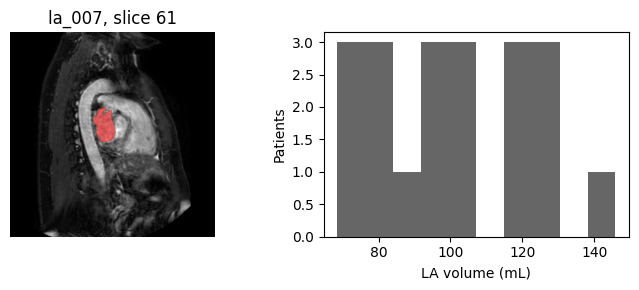

In [10]:
# first volume of the dataset and its manual segmentation
first = meta["training"][0]
x = nib.load(DATA_ROOT / first["image"]).get_fdata(dtype=np.float32)
y = np.asarray(nib.load(DATA_ROOT / first["label"]).dataobj) > 0
z = int(np.argmax(y.sum(axis=(0, 1))))  # slice with the largest LA area

fig, ax = plt.subplots(1, 2, figsize=(7, 3))
# left: MRI slice with the LA in orange on top
ax[0].imshow(np.rot90(x[:, :, z]), cmap="gray")
ax[0].imshow(np.rot90(np.ma.masked_where(~y[:, :, z], y[:, :, z])), cmap="autumn", alpha=0.5)
ax[0].set_title(f"{df.loc[0, 'case']}, slice {z}")
ax[0].axis("off")
# right: histogram of the LA volumes
ax[1].hist(df["la_volume_ml"], bins=10, color="0.4")
ax[1].set_xlabel("LA volume (mL)")
ax[1].set_ylabel("Patients")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_dataset.png", dpi=300)
plt.show()